# MLP for Multi-class Classification: Iris Dataset

## 1. Setup and Data Loading

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Create a DataFrame for easier viewing
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = iris.target_names[y]

print("Dataset loaded successfully.")

Dataset loaded successfully.


### Dataset Examples

In [42]:
# Display the first few rows of the dataset
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Distribution of Classes

/tmp/ipykernel_815/2651128158.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='species', data=df, palette='viridis')


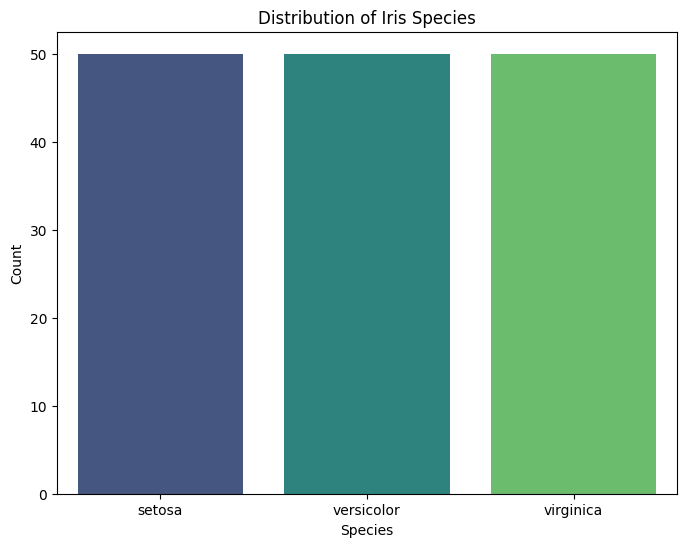

In [43]:
# Visualize the distribution of classes
plt.figure(figsize=(8, 6))
sns.countplot(x='species', data=df, palette='viridis')
plt.title('Distribution of Iris Species')
plt.xlabel('Species')
plt.ylabel('Count')
plt.show()

### Feature Distributions and Non-linearity

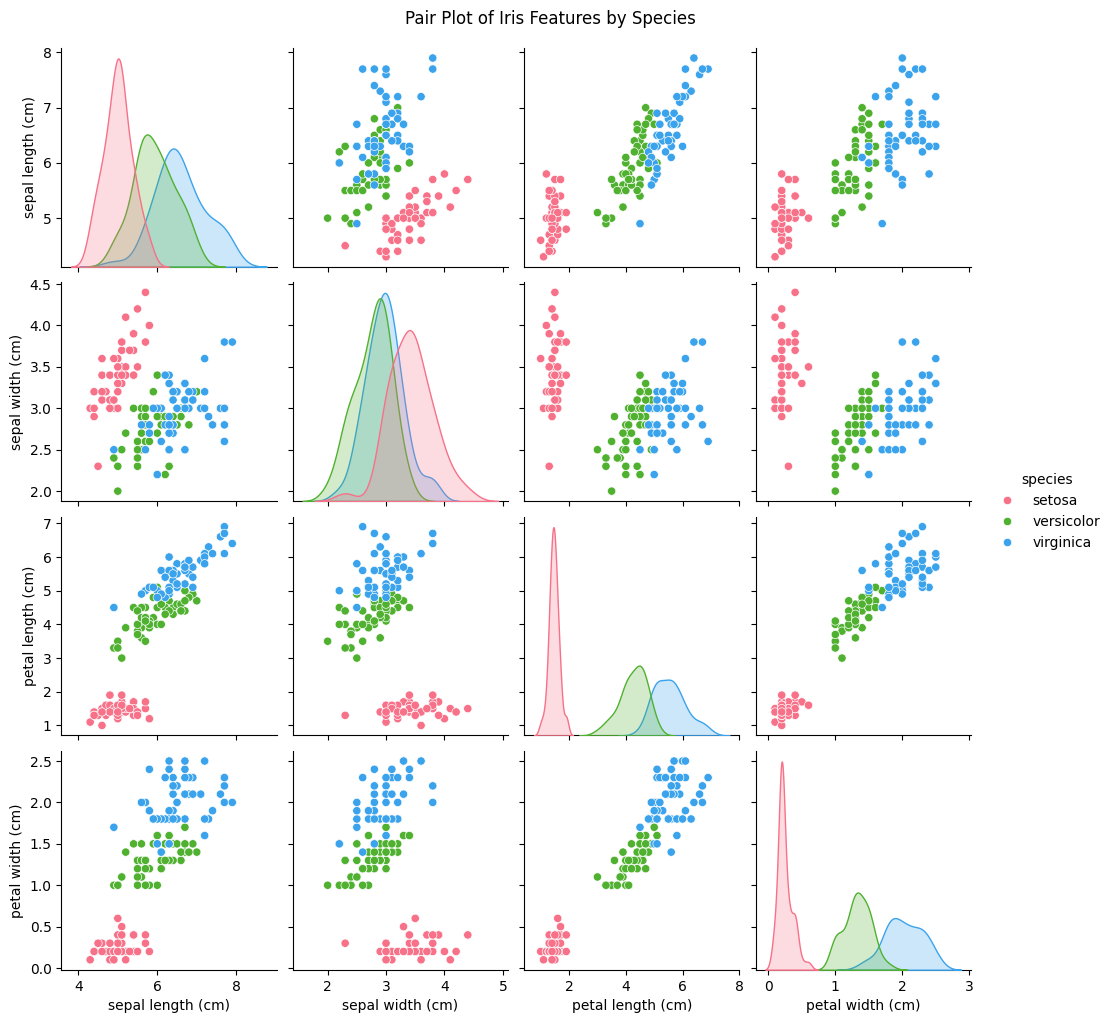

In [44]:
# Visualize feature distributions using a pair plot to observe non-linearity
sns.pairplot(df, hue='species', palette='husl')
plt.suptitle('Pair Plot of Iris Features by Species', y=1.02) # Adjust suptitle position
plt.show()

## 2. Data Preprocessing

In [45]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)


### Feature Scaling

In [46]:
# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully.")

Features scaled successfully.


### One-Hot Encoding for Target Variable

In [47]:
# One-hot encode target variable
encoder = OneHotEncoder(sparse_output=False)
y_train_encoded = encoder.fit_transform(y_train.reshape(-1, 1))
y_test_encoded = encoder.transform(y_test.reshape(-1, 1))

num_classes = y_train_encoded.shape[1]
print(f"Target variable one-hot encoded. Number of classes: {num_classes}")
print(f"y_train_encoded shape: {y_train_encoded.shape}")

Target variable one-hot encoded. Number of classes: 3
y_train_encoded shape: (120, 3)


## 3. Build and Compile the MLP Model

In [48]:
# Define the MLP model
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation='tanh'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='tanh'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax') # Output layer with softmax for multi-class classification
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 723 (2.82 KB)

 Trainable params: 723 (2.82 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the Model

In [49]:
history = model.fit(
    X_train_scaled, y_train_encoded,
    epochs=100,
    batch_size=5,
    validation_split=0.2,
    verbose=1 # Set to 1 or 2 for more verbose output
)

print("Model trained successfully.")

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4062 - loss: 1.0657 - val_accuracy: 0.6667 - val_loss: 0.8598
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6771 - loss: 0.7606 - val_accuracy: 0.7500 - val_loss: 0.6782
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7500 - loss: 0.6314 - val_accuracy: 0.7917 - val_loss: 0.5811
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7917 - loss: 0.5794 - val_accuracy: 0.7917 - val_loss: 0.5222
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8021 - loss: 0.5047 - val_accuracy: 0.7917 - val_loss: 0.4874
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8125 - loss: 0.4541 - val_accuracy: 0.8333 - val_loss: 0.4565
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8125 - loss: 0.4575 - val_accuracy: 0.8333 - val_loss: 0.4262
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8438 - loss: 0.3950 - val_accuracy: 0.8333 - 

### Plotting Training History (Error/Loss)

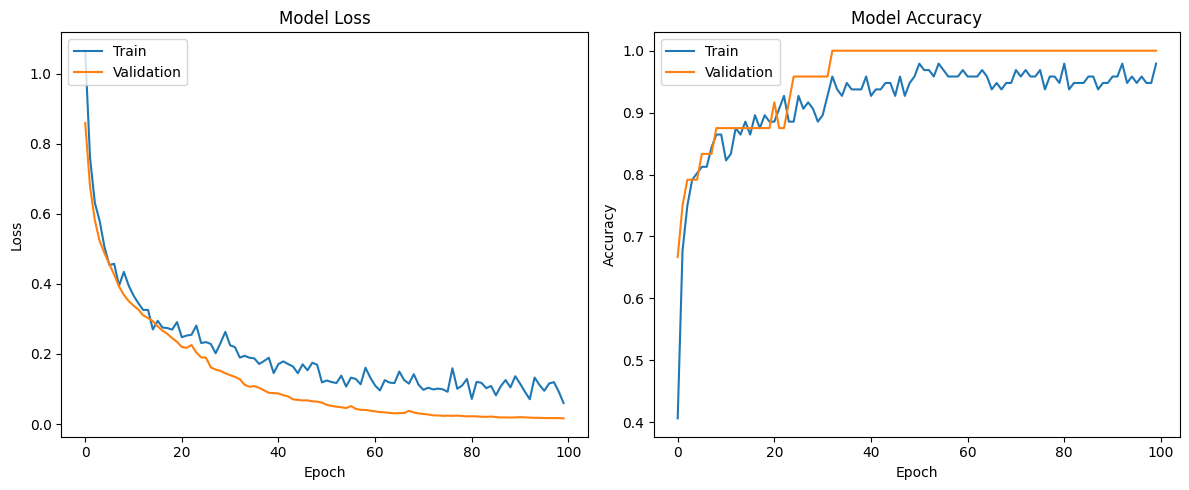

In [50]:
# Plot training & validation loss values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation accuracy values
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

## 5. Evaluate the Model

In [51]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_scaled, y_test_encoded, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss: 0.0875
Test Accuracy: 0.9333


### Classification Report and Confusion Matrix

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



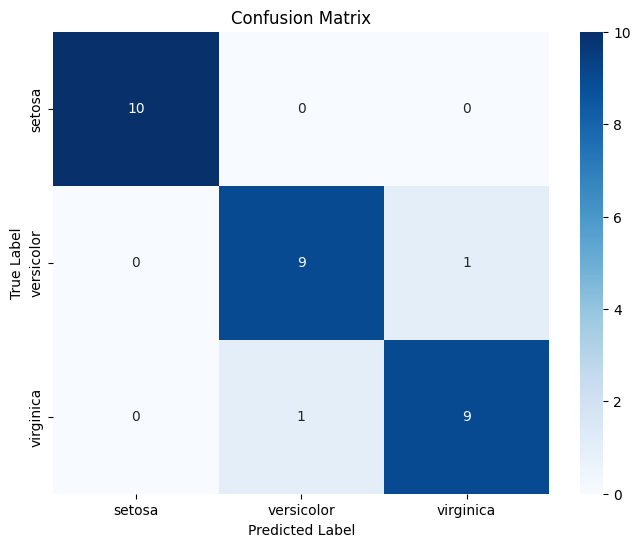

In [52]:
# Predict probabilities for the test set
y_pred_probs = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test

# Display classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=iris.target_names))

# Display confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Predictions vs. Target Examples

In [53]:
# Show some examples of predictions vs. target
print("\nSome examples of Predictions vs. Actual Target:")
results_df = pd.DataFrame({
    'True Label': iris.target_names[y_true],
    'Predicted Label': iris.target_names[y_pred],
    'Correct': (y_true == y_pred)
})
display(results_df.sample(min(10, len(results_df)), random_state=42)) # Display up to 10 random samples


Some examples of Predictions vs. Actual Target:


,True Label,Predicted Label,Correct
27,setosa,setosa,True
15,setosa,setosa,True
23,virginica,versicolor,False
17,versicolor,versicolor,True
8,virginica,virginica,True
9,versicolor,versicolor,True
28,virginica,virginica,True
24,virginica,virginica,True
12,virginica,virginica,True
0,setosa,setosa,True
